# PneumoScan-X: Leak-Free Chest X-Ray Triage with Explainable Grad-CAM++

**Veritas AI International High School Hackathon 2026 · PROJECT SUBMISSION**

* **Track:** AI + Health  
* **Team:** Erlangga Azhar & Affan Alhafiz Hikren (SMA Negeri 1 Kota Cilegon, Indonesia)  
* **Live Clinical Triage Web App:** [pneumoscan-x.streamlit.app](https://pneumoscan-x.streamlit.app/)  
* **GitHub Repository:** [github.com/erlangga-azhar/PneumoScan-X](https://github.com/erlangga-azhar/PneumoScan-X)

**One-sentence pitch:** PneumoScan-X helps frontline clinicians in rural clinics without on-site radiologists prioritize high-risk chest X-rays for pneumonia, highlighting suspicious lung regions with Grad-CAM++ while eliminating patient-level dataset leakage.

**How to run:** Click **Runtime → Restart session and run all**. This notebook automatically fetches our engine module (`pneumoscan_engine.py`), pre-trained weights (`best_mobilenet_pneumonia.pth`), and the public Kaggle Chest X-Ray dataset—no manual uploads or API keys required.

> *Medical Disclaimer: This research prototype is intended strictly for clinical triage decision-support research and educational benchmarking. It is not a certified medical device and does not constitute medical advice.*

## 1. Load & deduplicate the data

We use the **Chest X-Ray Images (Pneumonia)** dataset (Kermany et al. / Paul Mooney, Kaggle), fetched automatically via `kagglehub`. During initial inspection, we discovered a major structural flaw in the public archive: it contains nested duplicate directories (`chest_xray/chest_xray/`) and byte-identical copies across splits, inflating the raw file count to **11,712 images**.

We enforce strict deduplication via **MD5 byte-hashing** and path filtering inside `pneumoscan_engine.py`, reducing the dataset to **5,824 strictly unique radiographs** across **2,789 unique patients**.

In [1]:
!pip install -q grad-cam opencv-python-headless kagglehub

import contextlib
import copy
import io
import os
import time
import urllib.request

import cv2
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
import kagglehub
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    fbeta_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Auto-fetch engine & pre-trained weights from our public GitHub repo if not already local
GITHUB_RAW_BASE = "https://raw.githubusercontent.com/erlangga-azhar/PneumoScan-X/main"
for fname in ["pneumoscan_engine.py", "best_mobilenet_pneumonia.pth"]:
    if not os.path.exists(fname):
        url = f"{GITHUB_RAW_BASE}/{fname}"
        print(f"Fetching {fname} from GitHub...")
        urllib.request.urlretrieve(url, fname)

from pneumoscan_engine import (
    set_seed,
    extract_patient_id,
    prepare_dataset_splits,
    preprocess_xray_cv,
    XRayDataset,
    load_trained_model,
    find_optimal_threshold,
    format_clinical_triage,
    evaluate,
)

set_seed(42)
WEIGHTS_PATH = "best_mobilenet_pneumonia.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TF_EVAL = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Auto-download & extract public Kaggle dataset (no API key required)
LOCAL_DIRS = ["./dataset_raw", "./chest_xray", "/content/dataset_raw", "/content/chest_xray"]
DATA_DIR = next((d for d in LOCAL_DIRS if os.path.exists(d)), None)
if DATA_DIR is None:
    DATA_DIR = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

with contextlib.redirect_stdout(io.StringIO()):
    (train_files, train_lbls), (val_files, val_lbls), (test_files, test_lbls) = prepare_dataset_splits(DATA_DIR)

all_files = np.concatenate([train_files, val_files, test_files])
all_lbls = np.concatenate([train_lbls, val_lbls, test_lbls])
df_meta = pd.DataFrame({
    "filename": [os.path.basename(p) for p in all_files],
    "patient_id": [extract_patient_id(os.path.basename(p)) for p in all_files],
    "label": ["PNEUMONIA" if y == 1 else "NORMAL" for y in all_lbls],
    "is_pneumonia": all_lbls,
})

print(f"Hardware device  : {DEVICE}")
print(f"Verified dataset : {len(df_meta):,} unique radiographs across {df_meta['patient_id'].nunique():,} unique patients")
print(f"Class balance    : {df_meta['is_pneumonia'].sum():,} PNEUMONIA ({df_meta['is_pneumonia'].mean():.1%}) | {(1 - df_meta['is_pneumonia']).sum():,} NORMAL ({(1 - df_meta['is_pneumonia']).mean():.1%})")
df_meta.head(5)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Fetching pneumoscan_engine.py from GitHub...
Fetching best_mobilenet_pneumonia.pth from GitHub...
Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Hardware device  : cpu
Verified dataset : 5,824 unique radiographs across 2,789 unique patients
Class balance    : 4,245 PNEUMONIA (72.9%) | 1,579 NORMAL (27.1%)


,filename,patient_id,label,is_pneumonia
0,IM-0001-0001.jpeg,im-0001,NORMAL,0
1,IM-0003-0001.jpeg,im-0003,NORMAL,0
2,IM-0005-0001.jpeg,im-0005,NORMAL,0
3,IM-0006-0001.jpeg,im-0006,NORMAL,0
4,IM-0007-0001.jpeg,im-0007,NORMAL,0


## 2. Inspecting the data & mitigating clinical artifacts

Before training any neural network, we audited sample filenames, patient ID regex parsing across naming conventions (`person...`, `IM-...`, and `NORMAL2-IM-...`), and raw radiographs. Two domain findings shaped our preprocessing pipeline:
1. **Multi-scan patients & conservative ID grouping:** Multiple X-rays belong to the same patient (e.g., `person101_bacteria_483.jpeg` and `person101_bacteria_484.jpeg`). Furthermore, our regex conservatively normalizes both `IM-0007-0001.jpeg` and `NORMAL2-IM-0007-0001.jpeg` to `im-0007` so that even ambiguous ID collisions across hospital batches can never cross train/val/test boundaries.
2. **Border artifacts & exposure variance:** Raw hospital scans often contain bright white borders, portable `"A-P"` markers, and inconsistent exposure. We apply a **5% safe border crop** and **CLAHE (`clipLimit=1.5`, `8x8` tile grid)** to standardize pulmonary contrast.

Sample Pneumonia files (Patient ID extracted):
  - person101_bacteria_483.jpeg         -> patient_id: person101
  - person101_bacteria_484.jpeg         -> patient_id: person101
  - person101_bacteria_485.jpeg         -> patient_id: person101

Sample Normal files across naming prefixes (Patient ID extracted):
  - IM-0001-0001.jpeg                   -> patient_id: im-0001
  - IM-0003-0001.jpeg                   -> patient_id: im-0003
  - NORMAL2-IM-0007-0001.jpeg           -> patient_id: im-0007
  - NORMAL2-IM-0012-0001.jpeg           -> patient_id: im-0012


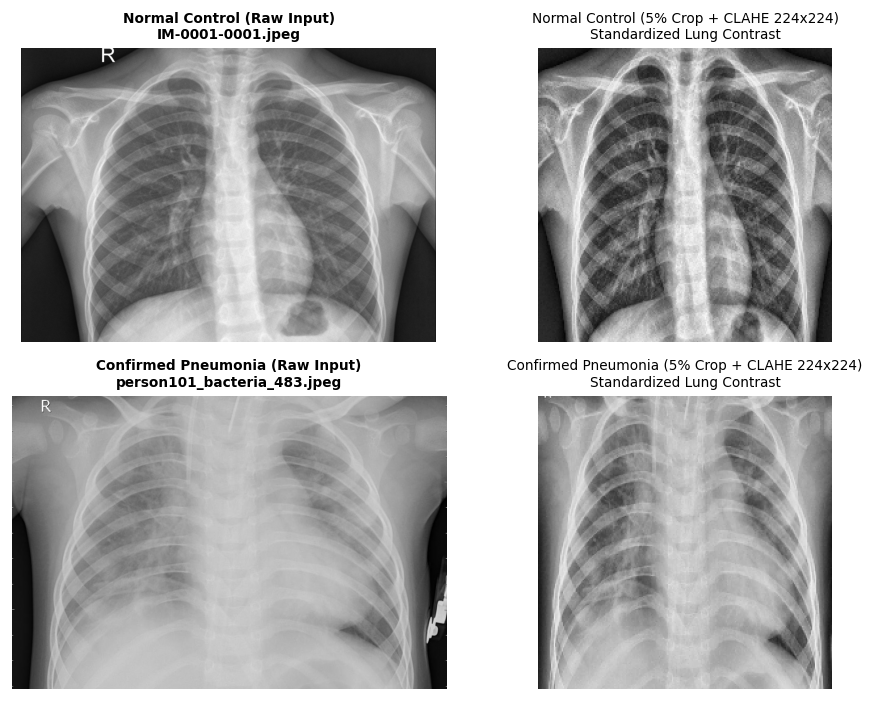

In [2]:
sample_pneu = [p for p, y in zip(train_files, train_lbls) if y == 1][:3]
sample_norm_im = [p for p, y in zip(train_files, train_lbls) if y == 0 and os.path.basename(p).startswith("IM-")][:2]
sample_norm_im2 = [p for p, y in zip(train_files, train_lbls) if y == 0 and "NORMAL2" in os.path.basename(p)][:2]

print("Sample Pneumonia files (Patient ID extracted):")
for p in sample_pneu:
    fname = os.path.basename(p)
    print(f"  - {fname:<35} -> patient_id: {extract_patient_id(fname)}")

print("\nSample Normal files across naming prefixes (Patient ID extracted):")
for p in sample_norm_im + sample_norm_im2:
    fname = os.path.basename(p)
    print(f"  - {fname:<35} -> patient_id: {extract_patient_id(fname)}")

# Visual verification: Raw scan vs. 5% Border-Cropped + CLAHE standardized input
fig, axes = plt.subplots(2, 2, figsize=(8.5, 6.2), dpi=115)
for row, (title_tag, sample_path) in enumerate([
    ("Normal Control", sample_norm_im[0]),
    ("Confirmed Pneumonia", sample_pneu[0]),
]):
    raw_gray = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)
    proc_rgb = preprocess_xray_cv(sample_path, validate_xray=False)

    axes[row, 0].imshow(raw_gray, cmap="gray")
    axes[row, 0].set_title(f"{title_tag} (Raw Input)\n{os.path.basename(sample_path)}", fontsize=8.5, fontweight="bold")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(proc_rgb)
    axes[row, 1].set_title(f"{title_tag} (5% Crop + CLAHE 224x224)\nStandardized Lung Contrast", fontsize=8.5)
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

## 3. Patient-aware train, validation, and test splits

We use `GroupShuffleSplit` grouped strictly by `patient_id` (Train: **3,969** | Validation: **943** | Test: **912**). We verify pairwise disjointness across **all three splits** (`Train ∩ Val = ∅`, `Train ∩ Test = ∅`, `Val ∩ Test = ∅`), guaranteeing zero anatomical data leakage during both threshold calibration and final test evaluation.

In [3]:
train_pids = {extract_patient_id(os.path.basename(p)) for p in train_files}
val_pids = {extract_patient_id(os.path.basename(p)) for p in val_files}
test_pids = {extract_patient_id(os.path.basename(p)) for p in test_files}

assert train_pids.isdisjoint(val_pids), "DATA LEAKAGE: Train and Val share patients!"
assert train_pids.isdisjoint(test_pids), "DATA LEAKAGE: Train and Test share patients!"
assert val_pids.isdisjoint(test_pids), "DATA LEAKAGE: Val and Test share patients!"

print(f"Train : {len(train_files):,} images ({len(train_pids):,} unique patients)")
print(f"Val   : {len(val_files):,} images ({len(val_pids):,} unique patients)")
print(f"Test  : {len(test_files):,} images ({len(test_pids):,} unique patients)")
print("Leakage check passed: 0 overlapping patients across Train, Val, and Test.")

Train : 3,969 images (1,952 unique patients)
Val   : 943 images (418 unique patients)
Test  : 912 images (419 unique patients)
Leakage check passed: 0 overlapping patients across Train, Val, and Test.


## 4. Baseline: trivial majority-class rule ("always predict pneumonia")

Because pneumonia makes up **71.49%** (652 of 912) of the unseen test set, a naive baseline that flags every single X-ray as pneumonia achieves 71.49% accuracy and 100.00% recall—but triggers **260 false alarms out of 260 healthy patients (0.00% specificity / 100.0% false-positive rate)**, overwhelming rural clinic workflows.

In [4]:
def bootstrap_ci(y_true, y_score, metric_fn, n_boot=1000, seed=42):
    """Compute 95% confidence interval via bootstrap resampling."""
    rng = np.random.default_rng(seed)
    n = len(y_true)
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        stats.append(metric_fn(y_true[idx], y_score[idx]))
    return float(np.percentile(stats, 2.5)), float(np.percentile(stats, 97.5))


def report_clinical_metrics(name, y_true, y_pred, y_prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    acc = accuracy_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred, zero_division=0)          # Sensitivity
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0              # Specificity
    prec = precision_score(y_true, y_pred, zero_division=0)    # PPV
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0.0               # Negative Predictive Value
    f2 = fbeta_score(y_true, y_pred, beta=2, zero_division=0)
    fp_rate = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    print(f"{name}")
    print(f"  Accuracy          : {acc:.2%}")
    print(f"  Sensitivity (Rec) : {rec:.2%}  (Missed pneumonia / FN: {fn} of {fn + tp})")
    print(f"  Specificity       : {spec:.2%}  (False alarms / FP: {fp} of {fp + tn} [{fp_rate:.2%}])")
    print(f"  Precision (PPV)   : {prec:.2%}")
    print(f"  Neg. Pred. Value  : {npv:.2%}  (Reliability when cleared as NORMAL)")
    print(f"  F2-Score          : {f2:.4f}")
    if y_prob is not None:
        roc_auc = roc_auc_score(y_true, y_prob)
        pr_auc = average_precision_score(y_true, y_prob)
        ci_low, ci_high = bootstrap_ci(y_true, y_prob, roc_auc_score)
        print(f"  ROC-AUC           : {roc_auc:.4f}  (95% CI: [{ci_low:.4f}, {ci_high:.4f}])")
        print(f"  PR-AUC (Avg Prec) : {pr_auc:.4f}")


baseline_preds = np.ones(len(test_lbls), dtype=int)
report_clinical_metrics("Baseline: Trivial Majority Rule (Always 'PNEUMONIA')", test_lbls, baseline_preds)

Baseline: Trivial Majority Rule (Always 'PNEUMONIA')
  Accuracy          : 71.49%
  Sensitivity (Rec) : 100.00%  (Missed pneumonia / FN: 0 of 652)
  Specificity       : 0.00%  (False alarms / FP: 260 of 260 [100.00%])
  Precision (PPV)   : 71.49%
  Neg. Pred. Value  : 0.00%  (Reliability when cleared as NORMAL)
  F2-Score          : 0.9261


## 5. Stage 1: Fine-tuned MobileNetV2 (default 0.50 cutoff) & CPU latency benchmark

Using the training pipeline in `pneumoscan_engine.py`, we fine-tuned **MobileNetV2** (unfreezing top convolutional blocks `features[14:]` with differential AdamW learning rates `1e-5` for backbone blocks and `1e-4` for the custom classification head, class-weighted Cross-Entropy loss `[n_pneumonia / n_normal, 1.0]`, and early stopping with patience `3` on validation F2) so it runs rapidly on standard clinic CPUs without requiring a discrete GPU.

Below we inspect parameter footprint, verify generalization across Validation vs. Unseen Test ROC-AUC, evaluate Stage 1 at the standard `0.50` cutoff, and benchmark **both** pure forward-pass and end-to-end single-radiograph CPU latency.

In [5]:
val_ds = XRayDataset(val_files, val_lbls, is_train=False)
test_ds = XRayDataset(test_files, test_lbls, is_train=False)

val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

model, saved_opt_thresh = load_trained_model(WEIGHTS_PATH, DEVICE)
total_params = sum(p.numel() for p in model.parameters())

_, _, _, val_auc, _, val_probs, val_targets = evaluate(model, val_loader, DEVICE, threshold=0.50)
_, _, _, test_auc, cm_50, test_probs, test_targets = evaluate(model, test_loader, DEVICE, threshold=0.50)

print(f"Backbone Footprint   -> MobileNetV2 ({total_params:,} parameters, ~{os.path.getsize(WEIGHTS_PATH)/1e6:.2f} MB checkpoint)")
print(f"Generalization Check -> Validation ROC-AUC: {val_auc:.4f} | Unseen Test ROC-AUC: {test_auc:.4f}\n")

pred_50 = (test_probs >= 0.50).astype(int)
report_clinical_metrics("Stage 1: Fine-Tuned MobileNetV2 (Default Cutoff = 0.50)", test_targets, pred_50, test_probs)
print("Confusion Matrix (Cutoff = 0.50):")
print(cm_50)

# Benchmark pure forward-pass AND end-to-end CPU latency (CLAHE preprocessing + tensor + forward pass)
model_cpu = copy.deepcopy(model).to("cpu").eval()
dummy_xray = torch.randn(1, 3, 224, 224)

with torch.no_grad():
    for _ in range(5):  # Warm-up runs
        _ = model_cpu(dummy_xray)
    fwd_ms, e2e_ms = [], []
    for _ in range(50):
        t0 = time.perf_counter()
        _ = model_cpu(dummy_xray)
        fwd_ms.append((time.perf_counter() - t0) * 1000.0)

        t1 = time.perf_counter()
        img_tensor, _, _ = test_ds[0]  # Includes disk read + 5% crop + CLAHE + normalization
        _ = model_cpu(img_tensor.unsqueeze(0))
        e2e_ms.append((time.perf_counter() - t1) * 1000.0)
del model_cpu

print(f"\nCPU Forward-Pass Latency (50 runs) : Mean = {np.mean(fwd_ms):.2f} ms | P95 = {np.percentile(fwd_ms, 95):.2f} ms")
print(f"CPU End-to-End Latency   (50 runs) : Mean = {np.mean(e2e_ms):.2f} ms | P95 = {np.percentile(e2e_ms, 95):.2f} ms")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 91.9MB/s]


Backbone Footprint   -> MobileNetV2 (2,388,098 parameters, ~9.80 MB checkpoint)
Generalization Check -> Validation ROC-AUC: 0.9882 | Unseen Test ROC-AUC: 0.9885

Stage 1: Fine-Tuned MobileNetV2 (Default Cutoff = 0.50)
  Accuracy          : 95.72%
  Sensitivity (Rec) : 96.93%  (Missed pneumonia / FN: 20 of 652)
  Specificity       : 92.69%  (False alarms / FP: 19 of 260 [7.31%])
  Precision (PPV)   : 97.08%
  Neg. Pred. Value  : 92.34%  (Reliability when cleared as NORMAL)
  F2-Score          : 0.9696
  ROC-AUC           : 0.9885  (95% CI: [0.9833, 0.9932])
  PR-AUC (Avg Prec) : 0.9955
Confusion Matrix (Cutoff = 0.50):
[[241  19]
 [ 20 632]]

CPU Forward-Pass Latency (50 runs) : Mean = 27.15 ms | P95 = 30.94 ms
CPU End-to-End Latency   (50 runs) : Mean = 79.45 ms | P95 = 89.19 ms


## 6. Stage 2 (Final): Validation-calibrated F2 triage cutoff (`0.50 → 0.12`) & patient-level check

In clinical triage, missing an active pneumonia case (False Negative) is far more dangerous than flagging a healthy scan for secondary physician review (False Positive). Rather than retraining a separate network, we perform **post-hoc decision calibration** strictly on the **Validation Set** to maximize **F2-Score** (weighting Recall 2× higher than Precision), locking the optimal cutoff at **`0.12`**.

On the unseen test set, lowering the cutoff from `0.50` to `0.12` reduces missed pneumonia radiographs by **65.0%** (from **20** down to **7** out of 652), boosts **Negative Predictive Value (NPV) to 96.60%**, and maintains **76.54% specificity** (cutting false alarms by **76.5%** vs. the trivial baseline).

Validation-calibrated F2-optimal threshold: 0.12 (Val F2: 0.9861)

Stage 2 (Final): PneumoScan-X + F2 Triage Calibration (Cutoff = 0.12)
  Accuracy          : 92.54%
  Sensitivity (Rec) : 98.93%  (Missed pneumonia / FN: 7 of 652)
  Specificity       : 76.54%  (False alarms / FP: 61 of 260 [23.46%])
  Precision (PPV)   : 91.36%
  Neg. Pred. Value  : 96.60%  (Reliability when cleared as NORMAL)
  F2-Score          : 0.9731
  ROC-AUC           : 0.9885  (95% CI: [0.9833, 0.9932])
  PR-AUC (Avg Prec) : 0.9955
Confusion Matrix (Final Cutoff = 0.12):
[[199  61]
 [  7 645]]

Patient-Level Triage Check (419 unique test patients):
  Patient Sensitivity : 98.77%  (Missed pneumonia patients: 3 of 244)


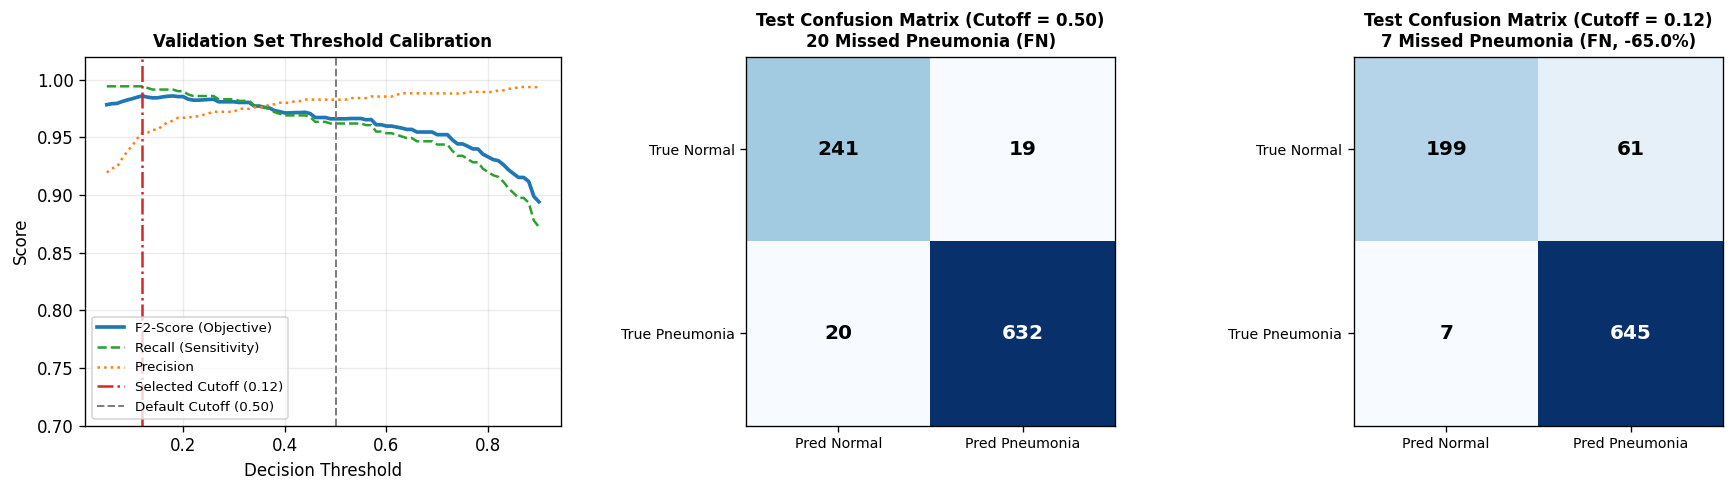

In [6]:
# Calibrate threshold strictly on Validation Set (never tuned on Test Set)
opt_thresh, val_f2 = find_optimal_threshold(val_targets, val_probs)
assert np.isclose(opt_thresh, saved_opt_thresh, atol=1e-2), (
    f"Threshold mismatch: live={opt_thresh:.2f} vs checkpoint={saved_opt_thresh:.2f}"
)
print(f"Validation-calibrated F2-optimal threshold: {opt_thresh:.2f} (Val F2: {val_f2:.4f})\n")

# Apply calibrated cutoff directly to unseen test probabilities (no redundant forward pass)
pred_opt = (test_probs >= opt_thresh).astype(int)
cm_f = confusion_matrix(test_targets, pred_opt)

report_clinical_metrics(
    f"Stage 2 (Final): PneumoScan-X + F2 Triage Calibration (Cutoff = {opt_thresh:.2f})",
    test_targets,
    pred_opt,
    test_probs,
)
print("Confusion Matrix (Final Cutoff = 0.12):")
print(cm_f)

# Patient-level aggregation check (max predicted risk across all radiographs of each unique test patient)
df_test_patients = pd.DataFrame({
    "patient_id": [extract_patient_id(os.path.basename(p)) for p in test_files],
    "y_true": test_targets,
    "y_prob": test_probs,
}).groupby("patient_id", as_index=False).agg({"y_true": "max", "y_prob": "max"})

pat_pred = (df_test_patients["y_prob"] >= opt_thresh).astype(int)
pat_rec = recall_score(df_test_patients["y_true"], pat_pred)
pat_fn = int(((df_test_patients["y_true"] == 1) & (pat_pred == 0)).sum())
pat_pos = int((df_test_patients["y_true"] == 1).sum())
print(f"\nPatient-Level Triage Check ({len(df_test_patients)} unique test patients):")
print(f"  Patient Sensitivity : {pat_rec:.2%}  (Missed pneumonia patients: {pat_fn} of {pat_pos})")

# Plot 1: Validation Threshold Curve (F2, Recall, Precision) | Plot 2 & 3: Test Confusion Matrices (0.50 vs 0.12)
thresholds = np.linspace(0.05, 0.90, 86)
val_f2_curve, val_rec_curve, val_prec_curve = [], [], []
for th in thresholds:
    vp = (val_probs >= th).astype(int)
    val_f2_curve.append(fbeta_score(val_targets, vp, beta=2, zero_division=0))
    val_rec_curve.append(recall_score(val_targets, vp, zero_division=0))
    val_prec_curve.append(precision_score(val_targets, vp, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=120)

axes[0].plot(thresholds, val_f2_curve, label="F2-Score (Objective)", linewidth=2.2, color="#1f77b4")
axes[0].plot(thresholds, val_rec_curve, label="Recall (Sensitivity)", linestyle="--", color="#2ca02c")
axes[0].plot(thresholds, val_prec_curve, label="Precision", linestyle=":", color="#ff7f0e")
axes[0].axvline(opt_thresh, color="#d62728", linestyle="-.", linewidth=1.5, label=f"Selected Cutoff ({opt_thresh:.2f})")
axes[0].axvline(0.50, color="#7f7f7f", linestyle="--", linewidth=1.2, label="Default Cutoff (0.50)")
axes[0].set_title("Validation Set Threshold Calibration", fontsize=10, fontweight="bold")
axes[0].set_xlabel("Decision Threshold")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0.70, 1.02)
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=8, loc="lower left")

for ax, cm_mat, title_str in [
    (axes[1], cm_50, "Test Confusion Matrix (Cutoff = 0.50)\n20 Missed Pneumonia (FN)"),
    (axes[2], cm_f, f"Test Confusion Matrix (Cutoff = {opt_thresh:.2f})\n7 Missed Pneumonia (FN, -65.0%)"),
]:
    ax.imshow(cm_mat, cmap="Blues")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Pred Normal", "Pred Pneumonia"], fontsize=8.5)
    ax.set_yticklabels(["True Normal", "True Pneumonia"], fontsize=8.5)
    ax.set_title(title_str, fontsize=10, fontweight="bold")
    for r in range(2):
        for c in range(2):
            color_txt = "white" if cm_mat[r, c] > cm_mat.max() / 2 else "black"
            ax.text(c, r, f"{cm_mat[r, c]}", ha="center", va="center", color=color_txt, fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

## 7. Where the model goes wrong (forensic error audit)

Even after F2 threshold optimization (`0.12`), clinical AI requires auditing every missed diagnosis. Inspecting all **7 false negatives** on the unseen test set—and rendering Grad-CAM++ saliency maps for our two primary failure cases—revealed two concrete failure modes:
1. **External medical artifacts:** On `person1453_bacteria_3770.jpeg` (predicted probability `0.0657`), Grad-CAM++ activation spilled onto circular ECG electrode pads and portable `"A-P"` markers outside the lung parenchyma.
2. **Subtle early viral infiltrates:** On `person1461_virus_2510.jpeg` (predicted probability `0.0439`), Grad-CAM++ localized bilateral lower-lobe opacity accurately, but faint contrast kept the probability below the `0.12` triage cutoff.

Total False Negatives at threshold 0.12: 7 of 652 pneumonia cases

  [MISSED PNEUMONIA] person1199_bacteria_3149.jpeg    | Pred Prob: 0.0617
  [MISSED PNEUMONIA] person1453_bacteria_3770.jpeg    | Pred Prob: 0.0657
  [MISSED PNEUMONIA] person1461_virus_2510.jpeg       | Pred Prob: 0.0439
  [MISSED PNEUMONIA] person277_virus_571.jpeg         | Pred Prob: 0.0086
  [MISSED PNEUMONIA] person435_virus_885.jpeg         | Pred Prob: 0.0568
  [MISSED PNEUMONIA] person781_virus_1412.jpeg        | Pred Prob: 0.0379
  [MISSED PNEUMONIA] person813_virus_1449.jpeg        | Pred Prob: 0.0716


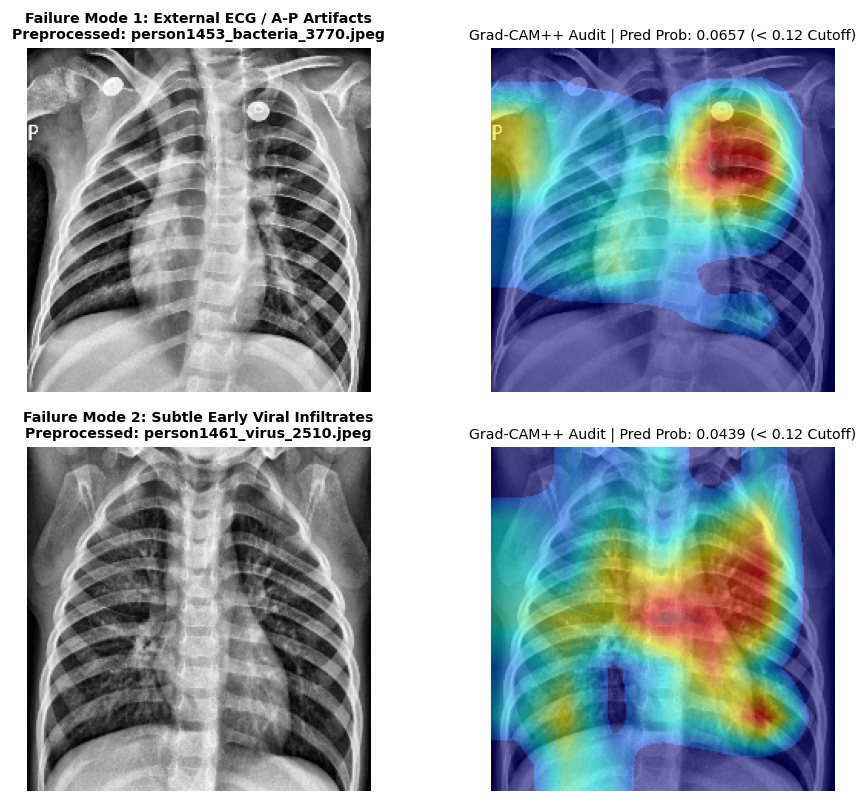

In [7]:
fn_indices = [i for i, (y, p) in enumerate(zip(test_targets, pred_opt)) if y == 1 and p == 0]

print(f"Total False Negatives at threshold {opt_thresh:.2f}: {len(fn_indices)} of {int(test_targets.sum())} pneumonia cases\n")
for idx in fn_indices:
    print(f"  [MISSED PNEUMONIA] {os.path.basename(test_files[idx]):<32} | Pred Prob: {test_probs[idx]:.4f}")

# Render visual Grad-CAM++ audit for the two documented failure modes
def find_test_file(target_name, fallback_idx=0):
    matches = [p for p in test_files if target_name in os.path.basename(p)]
    return matches[0] if matches else test_files[fn_indices[fallback_idx]]

audit_cases = [
    ("Failure Mode 1: External ECG / A-P Artifacts", find_test_file("person1453_bacteria_3770.jpeg", 0)),
    ("Failure Mode 2: Subtle Early Viral Infiltrates", find_test_file("person1461_virus_2510.jpeg", min(1, len(fn_indices) - 1))),
]

fig, axes = plt.subplots(len(audit_cases), 2, figsize=(8.5, 3.4 * len(audit_cases)), dpi=120)
target_block = model.features[-1]
prev_grad_states = [p.requires_grad for p in target_block.parameters()]

try:
    for p in target_block.parameters():
        p.requires_grad_(True)

    with GradCAMPlusPlus(model=model, target_layers=[target_block]) as cam:
        for row, (mode_title, path) in enumerate(audit_cases):
            img_np = preprocess_xray_cv(path, validate_xray=False)
            tensor = TF_EVAL(img_np).unsqueeze(0).to(DEVICE)

            with torch.no_grad():
                prob = torch.softmax(model(tensor), dim=1)[0, 1].item()

            with torch.enable_grad():
                cam_input = tensor.detach().requires_grad_(True)
                g_cam = cam(input_tensor=cam_input, targets=[ClassifierOutputTarget(1)])[0, :]

            g_cam[g_cam < 0.20] = 0.0
            overlay = show_cam_on_image(img_np.astype(np.float32) / 255.0, g_cam, use_rgb=True)

            axes[row, 0].imshow(img_np)
            axes[row, 0].set_title(f"{mode_title}\nPreprocessed: {os.path.basename(path)}", fontsize=8.5, fontweight="bold")
            axes[row, 0].axis("off")

            axes[row, 1].imshow(overlay)
            axes[row, 1].set_title(f"Grad-CAM++ Audit | Pred Prob: {prob:.4f} (< {opt_thresh:.2f} Cutoff)", fontsize=8.5)
            axes[row, 1].axis("off")
finally:
    model.zero_grad(set_to_none=True)
    for p, state in zip(target_block.parameters(), prev_grad_states):
        p.requires_grad_(state)

plt.tight_layout()
plt.show()

## 8. Our addition: Out-of-Distribution (OOD) guard & 3-tier clinical triage

**This is the safety engineering we added beyond a raw classifier.** A standard PyTorch model will silently convert any uploaded color photo (such as a smartphone camera snap or landscape image) into grayscale and output a false medical prediction. We added:
1. **RGB Channel-Variance OOD Guard:** Rejects non-grayscale color images prior to inference (`ValueError`). *(Note: Because this lightweight check inspects RGB channel divergence, monochromatic non-chest images remain an out-of-scope edge case addressed in Section 11 via planned U-Net lung segmentation.)*
2. **3-Tier Clinical Triage Mapping:** Translates raw pneumonia probabilities into actionable clinic workflows—*Normal / Low Risk* (`< 0.12`), *Suspect / Priority Review* (`0.12–0.50`), and *High-Probability Pneumonia* (`>= 0.50`), displaying both the raw probability and relative tier distance (`Tier Margin`).

In [8]:
# 1. Verify RGB Channel-Variance OOD Guard blocks accidental color photos
fake_color_photo = np.zeros((224, 224, 3), dtype=np.uint8)
fake_color_photo[:, :, 2] = 220  # Strong red channel

try:
    preprocess_xray_cv(fake_color_photo, validate_xray=True)
    print("OOD Guard FAILED: Color image was accepted.")
except ValueError:
    print("OOD Guard PASSED -> Input rejected: Non-grayscale color photo detected (exceeds RGB channel-variance tolerance).\n")

# 2. Verify 3-tier triage mapping across sample probabilities
TIER_ACTIONS_EN = {
    "NORMAL / LOW RISK": "No significant consolidation pattern detected. Routine clinical follow-up.",
    "SUSPECT / PRIORITY REVIEW": "Early/borderline opacity above F2 cutoff (0.12). Prioritize secondary physician review.",
    "HIGH PROBABILITY PNEUMONIA": "Strong pulmonary consolidation signature (>= 0.50). Expedite immediate clinical intervention.",
}

for sample_p in [0.01, 0.24, 0.96]:
    tier, _, tier_margin = format_clinical_triage(sample_p, threshold=opt_thresh)
    action_en = TIER_ACTIONS_EN.get(tier, "")
    print(f"Pneumonia Prob: {sample_p:6.1%} -> [{tier}] (Tier Margin: {tier_margin:.1f}%) | {action_en}")

OOD Guard PASSED -> Input rejected: Non-grayscale color photo detected (exceeds RGB channel-variance tolerance).

Pneumonia Prob:   1.0% -> [NORMAL / LOW RISK] (Tier Margin: 91.7%) | No significant consolidation pattern detected. Routine clinical follow-up.
Pneumonia Prob:  24.0% -> [SUSPECT / PRIORITY REVIEW] (Tier Margin: 59.5%) | Early/borderline opacity above F2 cutoff (0.12). Prioritize secondary physician review.
Pneumonia Prob:  96.0% -> [HIGH PROBABILITY PNEUMONIA] (Tier Margin: 98.4%) | Strong pulmonary consolidation signature (>= 0.50). Expedite immediate clinical intervention.


## 9. The demo: PneumoScan-X triage & Grad-CAM++ explainability across risk tiers

For every radiograph across the three triage zones, **Grad-CAM++** (activation cutoff `0.20`) highlights the exact pulmonary regions driving the score so clinicians can verify parenchymal localization before acting on a triage alert.

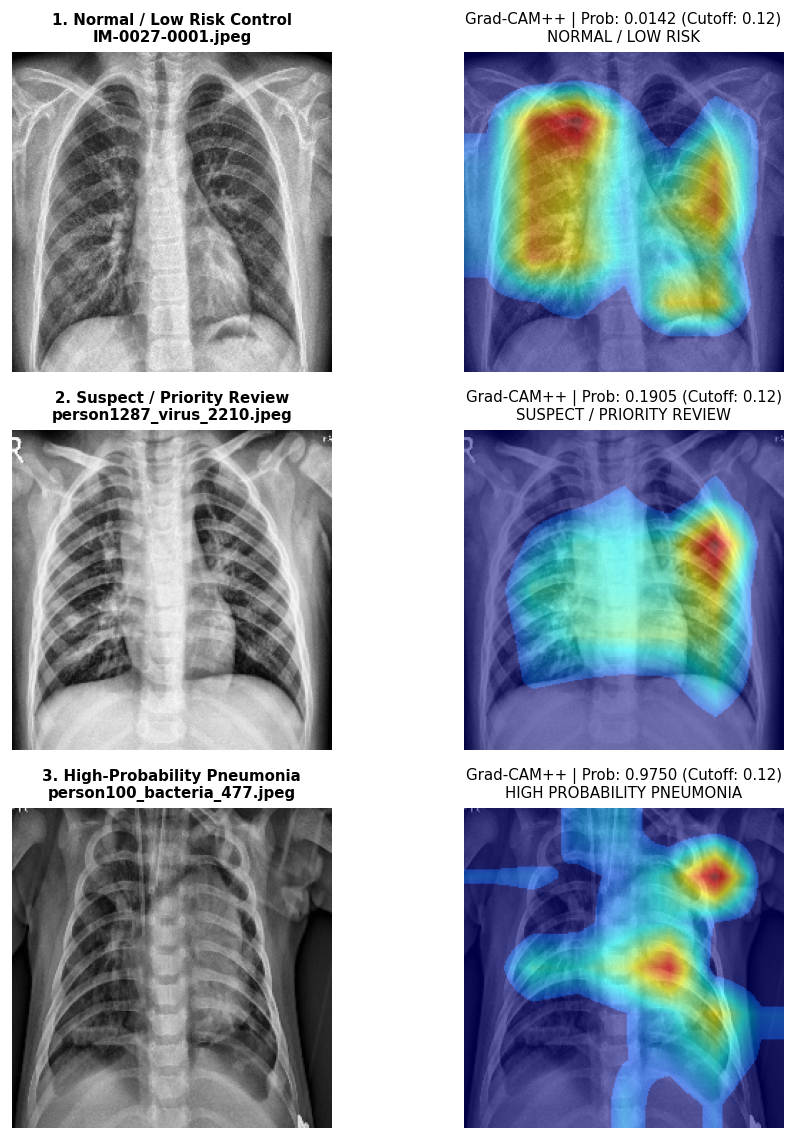

In [9]:
normal_p = [p for p, y, pr in zip(test_files, test_targets, test_probs) if y == 0 and pr < 0.02][0]
suspect_p = [p for p, y, pr in zip(test_files, test_targets, test_probs) if y == 1 and (opt_thresh <= pr <= 0.35)][0]
high_p = [p for p, y, pr in zip(test_files, test_targets, test_probs) if y == 1 and pr > 0.95][0]

demo_cases = [
    ("1. Normal / Low Risk Control", normal_p),
    ("2. Suspect / Priority Review", suspect_p),
    ("3. High-Probability Pneumonia", high_p),
]

fig, axes = plt.subplots(len(demo_cases), 2, figsize=(8.5, 3.2 * len(demo_cases)), dpi=120)
target_block = model.features[-1]
prev_grad_states = [p.requires_grad for p in target_block.parameters()]

try:
    for p in target_block.parameters():
        p.requires_grad_(True)

    with GradCAMPlusPlus(model=model, target_layers=[target_block]) as cam:
        for row, (label_title, path) in enumerate(demo_cases):
            img_np = preprocess_xray_cv(path, validate_xray=False)
            tensor = TF_EVAL(img_np).unsqueeze(0).to(DEVICE)

            with torch.no_grad():
                prob = torch.softmax(model(tensor), dim=1)[0, 1].item()
            tier, _, _ = format_clinical_triage(prob, threshold=opt_thresh)

            with torch.enable_grad():
                cam_input = tensor.detach().requires_grad_(True)
                g_cam = cam(input_tensor=cam_input, targets=[ClassifierOutputTarget(1)])[0, :]

            g_cam[g_cam < 0.20] = 0.0
            overlay = show_cam_on_image(img_np.astype(np.float32) / 255.0, g_cam, use_rgb=True)

            axes[row, 0].imshow(img_np)
            axes[row, 0].set_title(f"{label_title}\n{os.path.basename(path)}", fontsize=9, fontweight="bold")
            axes[row, 0].axis("off")

            axes[row, 1].imshow(overlay)
            axes[row, 1].set_title(f"Grad-CAM++ | Prob: {prob:.4f} (Cutoff: {opt_thresh:.2f})\n{tier}", fontsize=9)
            axes[row, 1].axis("off")
finally:
    model.zero_grad(set_to_none=True)
    for p, state in zip(target_block.parameters(), prev_grad_states):
        p.requires_grad_(state)

plt.tight_layout()
plt.show()

**Optional interactive clinical web app:** Set `RUN_APP = True` to launch the full bilingual (EN/ID) Streamlit triage interface (`app.py`). It is disabled by default so **Runtime → Restart session and run all** completes cleanly without blocking.

In [10]:
RUN_APP = False
if RUN_APP:
    !pip install -q streamlit
    !streamlit run app.py

## 10. Results summary (Unseen Test Set, N = 912 radiographs / 419 unique patients)

| Evaluation Metric | Trivial Baseline (Always Pneumonia) | Stage 1: MobileNetV2 (Cutoff = 0.50) | Stage 2: PneumoScan-X (F2 Cutoff = 0.12) |
| :--- | :---: | :---: | :---: |
| **Accuracy** | 71.49% | **95.72%** | 92.54% |
| **Sensitivity (Recall)** | 100.00% | 96.93% | **98.93%** |
| **Specificity** | 0.00% | **92.69%** | 76.54% |
| **Precision (PPV)** | 71.49% | **97.08%** | 91.36% |
| **Negative Predictive Value (NPV)** | — | 92.34% | **96.60%** |
| **F2-Score** | 0.9261 | 0.9696 | **0.9731** |
| **ROC-AUC** | 0.5000 | **0.9885** | **0.9885** |
| **Missed Cases (FN)** | 0 / 652 (0.00%) | 20 / 652 (3.07%) | **7 / 652 (1.07%)** |
| **False Alarms (FP Rate)** | 260 / 260 (100.0%) | 19 / 260 (7.31%) | **61 / 260 (23.46%)** |

On unseen patients (`N = 912`), PneumoScan-X achieves an **AUC-ROC of 0.9885**, reduces missed pneumonia diagnoses by **65.0%** compared to the standard `0.50` cutoff (from 20 down to 7 cases), achieves **96.60% Negative Predictive Value** when clearing a radiograph as low-risk, and cuts false alarms by **76.5%** compared to the trivial baseline.

## 11. Limitations, failure modes & engineering roadmap

To ensure rigorous scientific and clinical transparency, we explicitly document six technical and clinical limitations identified during our audit—along with concrete engineering steps to resolve each one in future iterations:

1. **External Medical Hardware Artifacts & Monochromatic OOD Blind Spot:**
   * *Limitation:* As shown in Section 7 (`person1453_bacteria_3770.jpeg`), external ECG electrode leads and portable `"A-P"` markers can pull Grad-CAM++ saliency away from lung parenchyma. In addition, our lightweight RGB channel-variance check (`_assert_grayscale_xray`) blocks color photos but cannot reject monochromatic non-chest inputs (e.g., hand/limb radiographs or grayscale camera images).
   * *Next Step:* Prepend a **lightweight U-Net lung-field segmentation mask** and anatomical mask-area gate prior to classification so the classifier only attends to verified pulmonary parenchyma and automatically rejects non-thoracic grayscale inputs.

2. **Uncalibrated Softmax Probabilities:**
   * *Limitation:* Because the network is trained with class-weighted Cross-Entropy (`[n_pneumonia / n_normal, 1.0]`) and evaluated at an F2-tuned cutoff (`0.12`), raw output probabilities represent relative triage risk scores rather than calibrated epidemiological probabilities.
   * *Next Step:* Apply **Temperature Scaling / Platt Calibration** on validation logits and report **Expected Calibration Error (ECE)** and **Brier Score** so clinicians see well-calibrated risk percentages.

3. **Binary Formulation Without Differential Diagnosis:**
   * *Limitation:* PneumoScan-X currently performs binary triage (`NORMAL` vs. `PNEUMONIA`) and does not differentiate bacterial vs. viral etiology or screen for high-burden thoracic differentials in Indonesian primary care such as **Tuberculosis (TB)**, pleural effusion, or cardiomegaly.
   * *Next Step:* Extend the classification head to multi-label thoracic pathology detection using large-scale public cohorts (NIH ChestX-ray14, CheXpert, PadChest) enriched with regional TB radiographs.

4. **Single-Center Pediatric Cohort & Projection Domain Shift:**
   * *Limitation:* The underlying Kaggle dataset consists primarily of retrospective pediatric radiographs (ages 1–5) from Guangzhou Women and Children's Medical Center. Rural *Puskesmas* clinics serve adult and geriatric patients with different thoracic anatomy, comorbidities, and acquisition projections (upright PA vs. portable supine AP).
   * *Next Step:* Conduct multi-center external validation across adult and geriatric Indonesian hospital cohorts and report subgroup sensitivity stratified by age, sex, and AP/PA view.

5. **Training History Logging & Drift Auditing:**
   * *Limitation:* Training execution is encapsulated in `pneumoscan_engine.py`, and the serialized checkpoint stores model weights plus `optimal_threshold` without persisting per-epoch training/validation loss and F2 curves inside the artifact.
   * *Next Step:* Serialize full per-epoch training histories inside `.pth` metadata and render convergence curves directly within the reproducibility notebook.

6. **Prospective Clinical Reader Study & Regulatory Readiness:**
   * *Limitation:* Current metrics reflect retrospective offline evaluation and have not yet been tested in live clinical workflows or undergone medical device certification (Kemenkes RI / FDA / CE).
   * *Next Step:* Partner with general practitioners in a prospective human-AI reader study to quantify triage turnaround time and diagnostic sensitivity with vs. without Grad-CAM++ assistance.

## Sources & Credits

- **Dataset:** Kermany, D., Zhang, K., & Goldbaum, M. (2018). *Labeled Optical Coherence Tomography (OCT) and Chest X-Ray Images for Classification* (hosted on Kaggle by Paul Mooney: `https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia`).
- **Frameworks & Libraries:** PyTorch, Torchvision (`MobileNetV2` ImageNet weights), OpenCV (`opencv-python-headless`), `pytorch-grad-cam`, Scikit-learn, Pandas, NumPy, Streamlit.
- **Development & AI Tools:** Google Colab (training and evaluation), GitHub (version control), and AI coding assistants for OpenCV/Grad-CAM++ debugging and Streamlit UI scaffolding, with all data splits, statistical intervals, and clinical evaluation metrics verified independently.